## NumPy_NN
Реализуем кастомную полносвязную нейронную сеть на NumPy


In [148]:
import numpy as np


class ReLU:
    def __init__(self):
        self.input_mask = None

    def forward(self, X):
        self.input_mask = X > 0
        return np.where(self.input_mask, X, 0)

    def backward(self, input_grads):
        partial = np.where(self.input_mask, 1, 0)
        return partial * input_grads


In [149]:
class Linear:
    def __init__(self, d_in, d_out):
        rng = np.random.default_rng(seed=42)
        self.params = rng.normal(loc=0, scale=np.sqrt(2 / d_in), size=(d_in, d_out))
        self.bias = rng.normal(loc=0, scale=1, size=d_out)
        self.d_params = None
        self.d_bias = None
        self.input = None

    def forward(self, X):
        self.input = X
        return X @ self.params + self.bias

    def backward(self, input_grads):
        d_X = input_grads @ (self.params.T)
        self.d_params = (self.input.T) @ input_grads
        self.d_bias = np.sum(input_grads, axis=0)
        return d_X


In [150]:
class Softmax:
    def __init__(self):
        self.output = None

    def forward(self, X):
        m = np.max(X, axis=1, keepdims=True)
        s = np.sum(np.exp(X - m), axis=1, keepdims=True)
        self.output = np.exp(X - m) / s
        return self.output

    def backward(self, input_grads):
        d_X = self.output * (input_grads - np.sum(self.output * input_grads, axis=1, keepdims=True))
        return d_X

In [151]:
class CrossEntropyLoss:
    def __init__(self, model):
        self.eps = 1e-12
        self.input = None
        self.y = None
        self.model = model

    def loss(self, X, y):
        self.y = y
        self.input = X
        return -np.mean(np.log(X[np.arange(len(y)), y] + self.eps))

    def backward(self):
        grad = np.zeros_like(self.input)
        N = len(self.y)
        idx = np.arange(N)
        grad[idx, self.y] = -1.0 / (N * (self.input[idx, self.y] + self.eps))
        self.model.backward(grad)

    def __call__(self, X, y):
        return self.loss(X, y)


In [152]:
class Sequential:
    def __init__(self):
        self.layers = []

    def add_layer(self, layer):
        self.layers.append(layer)

    def forward(self, X):
        if not self.layers:
            print('Sequential is empty')
            return
        output = self.layers[0].forward(X)
        for layer in self.layers[1:]:
            output = layer.forward(output)
        return output

    def __repr__(self):
        ans = []
        for layer in self.layers:
            ans.append(type(layer).__name__)
        return ', '.join(ans)

    def backward(self, y):
        if not self.layers:
            print('Sequential is empty')
            return

        output = self.layers[-1].backward(y)
        for layer in self.layers[:-1][::-1]:
            output = layer.backward(output)

    def __call__(self, X):
        return self.forward(X)



In [153]:
class SGD:
    def __init__(self, model, lr=1e-2):
        self.lr = lr
        self.model = model

    def step(self):
        for layer in self.model.layers:
            if hasattr(layer, 'params'):
                layer.params -= layer.d_params * self.lr
            if hasattr(layer, 'bias'):
                layer.bias -= layer.d_bias * self.lr



In [154]:
import numpy as np
from sklearn.datasets import fetch_openml

X, y = fetch_openml("mnist_784", version=1, as_frame=False, return_X_y=True)

X = X.astype(np.float32) / 255.0   # (70000, 784), значения в [0, 1]
y = y.astype(np.int64)             # метки приходят строками -> индексы классов

X_train, y_train = X[:60000], y[:60000]
X_test, y_test = X[60000:], y[60000:]

print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)
# (60000, 784) (60000,) (10000, 784) (10000,)

(60000, 784) (60000,) (10000, 784) (10000,)


In [155]:
model = Sequential()
model.add_layer(Linear(784, 128))
model.add_layer(ReLU())
model.add_layer(Linear(128, 10))
model.add_layer(Softmax())

criterion = CrossEntropyLoss(model)
optimizer = SGD(model)

batch_size = 64
n_batches = len(X) // batch_size

X_batches = X[:n_batches * batch_size].reshape(n_batches, batch_size, -1)  # (n_batches, 64, 784)
y_batches = y[:n_batches * batch_size].reshape(n_batches, batch_size)      # (n_batches, 64)



for epoch in range(5):
    for i in range(n_batches):
        features = X_batches[i]
        labels = y_batches[i]

        logits = model(features)
        loss = criterion(logits, labels)
        criterion.backward()
        optimizer.step()




In [156]:
import matplotlib.pyplot as plt

step_losses = []    # лосс на каждом батче
epoch_losses = []   # средний лосс за эпоху
accuracies = []   # Точность на валидации за эпоху
test_length = len(y_test)

for epoch in range(50):
    running = 0.0
    for i in range(n_batches):
        features = X_batches[i]
        labels = y_batches[i]

        probs = model(features)
        loss = criterion(probs, labels)
        criterion.backward()
        optimizer.step()

        step_losses.append(loss)
        running += loss

    epoch_losses.append(running / n_batches)
    acc = (np.argmax(model(X_test), axis=1) == y_test).mean()
    accuracies.append(acc)
    print(f"epoch {epoch}: loss {epoch_losses[-1]:.4f}, accuracy {acc:.4f}")

epoch 0: loss 0.2782, accuracy 0.9284
epoch 1: loss 0.2650, accuracy 0.9314
epoch 2: loss 0.2530, accuracy 0.9341
epoch 3: loss 0.2421, accuracy 0.9373
epoch 4: loss 0.2320, accuracy 0.9403
epoch 5: loss 0.2227, accuracy 0.9425
epoch 6: loss 0.2140, accuracy 0.9452
epoch 7: loss 0.2058, accuracy 0.9474
epoch 8: loss 0.1982, accuracy 0.9496
epoch 9: loss 0.1911, accuracy 0.9513
epoch 10: loss 0.1844, accuracy 0.9527
epoch 11: loss 0.1781, accuracy 0.9544
epoch 12: loss 0.1722, accuracy 0.9559
epoch 13: loss 0.1667, accuracy 0.9573
epoch 14: loss 0.1615, accuracy 0.9587
epoch 15: loss 0.1566, accuracy 0.9602
epoch 16: loss 0.1520, accuracy 0.9618
epoch 17: loss 0.1478, accuracy 0.9628
epoch 18: loss 0.1437, accuracy 0.9643
epoch 19: loss 0.1399, accuracy 0.9654
epoch 20: loss 0.1362, accuracy 0.9658
epoch 21: loss 0.1328, accuracy 0.9665
epoch 22: loss 0.1295, accuracy 0.9677
epoch 23: loss 0.1264, accuracy 0.9689
epoch 24: loss 0.1235, accuracy 0.9693
epoch 25: loss 0.1207, accuracy 0.9

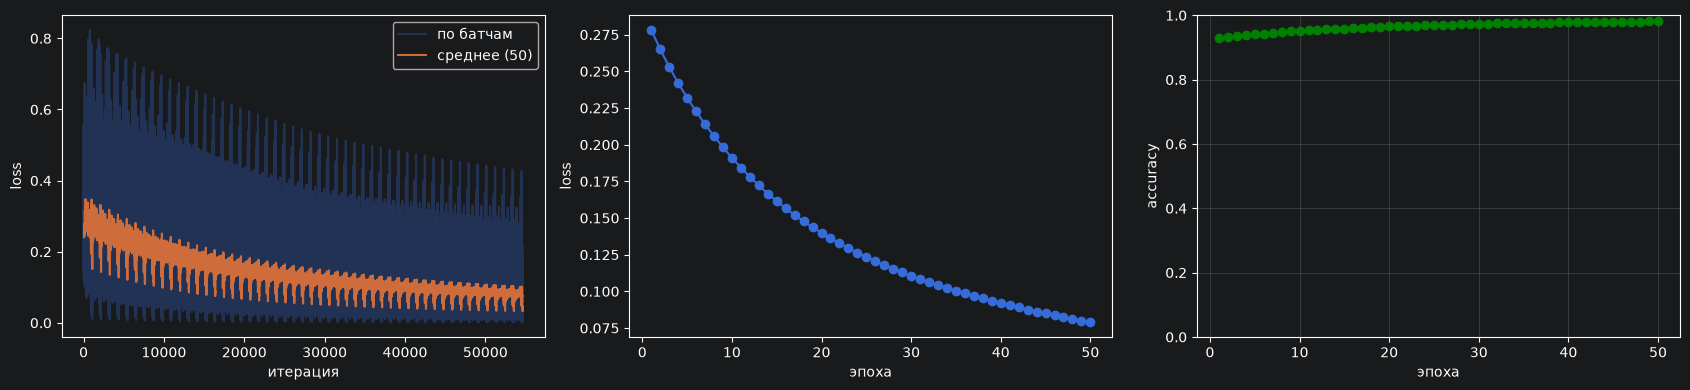

In [157]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))

# лосс по батчам + скользящее среднее
window = 50
smooth = np.convolve(step_losses, np.ones(window) / window, mode="valid")
axes[0].plot(step_losses, alpha=0.3, label="по батчам")
axes[0].plot(np.arange(window - 1, len(step_losses)), smooth, label=f"среднее ({window})")
axes[0].set_xlabel("итерация")
axes[0].set_ylabel("loss")
axes[0].legend()

# средний лосс по эпохам
epochs = range(1, len(epoch_losses) + 1)
axes[1].plot(epochs, epoch_losses, marker="o")
axes[1].set_xlabel("эпоха")
axes[1].set_ylabel("loss")

# точность на тесте по эпохам
axes[2].plot(epochs, accuracies, marker="o", color="green")
axes[2].set_xlabel("эпоха")
axes[2].set_ylabel("accuracy")
axes[2].set_ylim(0, 1)
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()